In [66]:
import numpy as np

In [67]:
from astropy import constants as const
from astropy import units as u

# Constants

r_s = const.R_sun.to(u.m).value.item() #UA
m_s= const.M_sun.to(u.kg).value.item() #kg
M_t= const.M_earth.to(u.kg).value.item() #kg
R_t= const.R_earth.to(u.m).value.item() #m
a=1.496e+11#m
mi_0=4*np.pi*10**(-7)


In [68]:
import pandas as pd

In [34]:
df=pd.read_csv('sigma_todos_exoplanetas.csv')

In [35]:
df1=pd.read_csv('dados fe artigo - Página1.csv')

In [88]:
V=[4.706, 5.093, 4.897, 5.500, 5.093, 5.093, 4.339]

#  Erro de sigma

In [90]:
def encontrar_x_com_incerteza_TP(T_art, P_art, temperatura, pressao, delta_T, delta_P):

    # Garante escalares
    temperatura = float(temperatura)
    pressao = float(pressao)
    delta_T = float(delta_T)
    delta_P = float(delta_P)
    
    def calcular_distancias(T, P):
        t_min, t_max = T_art.min(), T_art.max()
        p_min, p_max = P_art.min(), P_art.max()

        def norm(col, minimo, maximo):
            if maximo == minimo:
                return col * 0.0
            return (col - minimo) / (maximo - minimo)

        t_norm_col = norm(T_art, t_min, t_max)
        p_norm_col = norm(P_art, p_min, p_max)
        t_norm = norm(pd.Series([T]), t_min, t_max).iloc[0]
        p_norm = norm(pd.Series([P]), p_min, p_max).iloc[0]

        return ((t_norm_col - t_norm)**2 + (p_norm_col - p_norm)**2)**0.5

    def encontrar_V(T, P):
        distancias = calcular_distancias(T, P)
        idx = distancias.idxmin()
        return df1.loc[idx, 'Volume (cm3/mol)']

    V0 = encontrar_V(temperatura, pressao)

    dV_dT = (encontrar_V(temperatura + delta_T, pressao) -
             encontrar_V(temperatura - delta_T, pressao)) / (2 * delta_T)

    dV_dP = (encontrar_V(temperatura, pressao + delta_P) -
             encontrar_V(temperatura, pressao - delta_P)) / (2 * delta_P)

    delta_V_TP = np.sqrt((dV_dT * delta_T)**2 + (dV_dP * delta_P)**2)

    # Piso de discretização
    distancias = calcular_distancias(temperatura, pressao)
    idx_sorted = distancias.nsmallest(len(df1)).index
    volumes_vizinhos = df1.loc[idx_sorted, 'Volume (cm3/mol)']
    volumes_distintos = volumes_vizinhos[volumes_vizinhos != V0]

    if len(volumes_distintos) > 0:
        V2 = volumes_distintos.iloc[0]
        delta_V_disc = abs(V0 - V2) / 2
    else:
        delta_V_disc = 0.0

    delta_V = max(delta_V_TP, delta_V_disc)

    return delta_V

In [91]:
V_delta=[]
for i in np.arange(len(df2)):
    V_delta.append(encontrar_x_com_incerteza_TP(df1['Temperature (K)'], df1['Pexp (GPa)b'], df2['T_cmb_mean'][i], df2['P_cmb_mean'][i]/(10**9), df2['T_cmb_sigma'][i],  df2['P_cmb_sigma'][i]/(10**9)))

In [92]:
df['V_sigma']=V_delta

In [93]:
a=0.792
b=1.479
c=747.2
d=1405
rho_0=75.10
rho_1=21.48
T_0=2000
V_0=7.121

In [94]:
def erro_sigma(T, V, sigma_T, sigma_V):

    rho_bg=rho_0*(V/V_0)**a+rho_1*(V/V_0)**b*(T/T_0)
    rho_sat=c*(V/V_0)**(1/3)
    rho_el=d*(T_0/T)
    sigma_mean=(1/rho_bg)+(1/rho_sat)+(1/rho_el)


    A=rho_0*(V/V_0)**a
    B=rho_1*(V/V_0)**b
    delta_sgima_T=-(B/(T_0*(A+B*T/T_0)**2))+(1/(d*T_0))
    delta_sgima_V=-(((rho_0*a*V**(a-1)/V_0**a)+(rho_1*b*V**(b-1)/V_0**b))/(rho_0*(V/V_0)**a+(rho_1*T/T_0)*(V/V_0)**B)**2)-(V_0**(1/3)/(3*c*V**(4/3)))

    
    sigma_sigma=np.sqrt((delta_sgima_T*sigma_T)**2+(delta_sgima_V*sigma_V)**2)
    return sigma_mean, sigma_sigma

In [95]:
sigma_sigma=[]
sigma_mean=[]
for i in np.arange(len(df2)):
    sigma_mean.append(erro_sigma(df2['T_cmb_mean'][i], df2['V'][i], df2['T_cmb_sigma'][i],  df2['V_sigma'][i])[0]*10**8)
    sigma_sigma.append(erro_sigma(df2['T_cmb_mean'][i], df2['V'][i], df2['T_cmb_sigma'][i],  df2['V_sigma'][i])[1]*10**8)

In [96]:
df['sigma_sigma']=sigma_sigma
df['sigma_mean']=sigma_mean

# Campo e Erro

In [97]:
def campo_total(sigma, D, rho, R_m, r, K):
    
    Br=((1.38*K*R_m**2*D**2)/(4*sigma*r**3))*(np.sqrt(rho/mi_0)) #Tesla

    return Br

In [98]:
def campo_radial(sigma, D, rho, R_m, r, K):
    
    Br=((K*R_m**2*D**2)/(2*sigma*r**3))*(np.sqrt(rho/mi_0)) #Tesla

    return Br

In [99]:
def erro_campo(D, rp, rho,sigma, B, sigma_D, sigma_rho, sigma_rp, sigma_sigma):
    sigma=B*np.sqrt(((2*sigma_D)/D)**2+(sigma_rho/(2*rho))**2+((3*sigma_rp)/rp)**2+(sigma_sigma/sigma)**2)
    return sigma

In [100]:
K2=0.094

In [101]:
B1=[]
B_total=[]
B1_erro=[]

In [132]:
Rp=1.17*R_t
sigma=df.iloc[17]['sigma']
Rd=df.iloc[17]['Rc']
Rdi=df.iloc[17]['Ric']
D=Rd-Rdi
rho=df.iloc[17]['rho_core_mean']
R_m=800

In [102]:
#  Kepler-186 f
Rp=1.17*R_t
sigma=df.iloc[17]['sigma']
Rd=df.iloc[17]['Rc']
Rdi=df.iloc[17]['Ric']
D=Rd-Rdi
rho=df.iloc[17]['rho_core_mean']
R_m=800

B_r_sup=campo_radial(sigma, D, rho, R_m, Rp, K2)
B_r_sigma=erro_campo(D, Rp, rho, sigma, B_r_sup, df2['D_sigma'][0]*Rp, df2['rho_sigma'][0], 0.08*Rp, df2['sigma_sigma'][0])
B_tot=campo_total(sigma, D, rho, R_m, Rp, K2)
B1.append(B_r_sup*10**4)
B_total.append(B_tot*10**4)
B1_erro.append(B_r_sigma*10**4)

In [141]:
# Proxima Cen b
Rp=1.02*R_t
sigma=df.iloc[27]['sigma']
Rd=df.iloc[27]['Rc']
Rdi=df.iloc[27]['Ric']
D=Rd-Rdi
rho=df.iloc[27]['rho_core_mean']
R_m=800

In [106]:
# Proxima Cen b
Rp=1.02*R_t
sigma=df.iloc[27]['sigma']
Rd=df.iloc[27]['Rc']
Rdi=df.iloc[27]['Ric']
D=Rd-Rdi
rho=df.iloc[27]['rho_core_mean']
R_m=800


B_r_sup=campo_radial(sigma, D, rho, R_m, Rp, K2)
B_r_sigma=erro_campo(D, Rp, rho, sigma, B_r_sup, df2['D_sigma'][1], df2['rho_sigma'][1], 0.2*Rp, df2['sigma_sigma'][1])
B_tot=campo_total(sigma, D, rho, R_m, Rp, K2)
B1.append(B_r_sup*10**4)
B_total.append(B_tot*10**4)
B1_erro.append(B_r_sigma*10**4)

In [110]:
# TOI-700 d
Rp=1.073*R_t
sigma=df.iloc[31]['sigma']
Rd=df.iloc[31]['Rc']
Rdi=df.iloc[31]['Ric']
D=Rd-Rdi
rho=df.iloc[31]['rho_core_mean']
R_m=800

B_r_sup=campo_radial(sigma, D, rho, R_m, Rp, K2)
B_r_sigma=erro_campo(D, Rp, rho, sigma, B_r_sup, df2['D_sigma'][2]*Rp, df2['rho_sigma'][2], 0.059*Rp, df2['sigma_sigma'][2])
B_tot=campo_total(sigma, D, rho, R_m, Rp, K2)
B1.append(B_r_sup*10**4)
B_total.append(B_tot*10**4)
B1_erro.append(B_r_sigma*10**4)

In [114]:
# TOI-700 e
Rp=0.953*R_t
sigma=df.iloc[32]['sigma']
Rd=df.iloc[32]['Rc']
Rdi=df.iloc[32]['Ric']
D=Rd-Rdi
rho=df.iloc[32]['rho_core_mean']
R_m=800

B_r_sup=campo_radial(sigma, D, rho, R_m, Rp, K2)
B_r_sigma=erro_campo(D, Rp, rho, sigma, B_r_sup, df2['D_sigma'][3]*Rp, df2['rho_sigma'][3], 0.089*Rp, df2['sigma_sigma'][3])
B_tot=campo_total(sigma, D, rho, R_m, Rp, K2)
B1.append(B_r_sup*10**4)
B_total.append(B_tot*10**4)
B1_erro.append(B_r_sigma*10**4)

In [118]:
# Teegarden's Star b
Rp=1.05*R_t
sigma=df.iloc[34]['sigma']
Rd=df.iloc[34]['Rc']
Rdi=df.iloc[34]['Ric']
D=Rd-Rdi
rho=df.iloc[34]['rho_core_mean']
R_m=800

B_r_sup=campo_radial(sigma, D, rho, R_m, Rp, K2)
B_r_sigma=erro_campo(D, Rp, rho, sigma, B_r_sup, df2['D_sigma'][4]*Rp, df2['rho_sigma'][4], 0.2*Rp, df2['sigma_sigma'][4])
B_tot=campo_total(sigma, D, rho, R_m, Rp, K2)
B1.append(B_r_sup*10**4)
B_total.append(B_tot*10**4)
B1_erro.append(B_r_sigma*10**4)

In [74]:
# LHS 1140 b
Rp=1.73*R_t
sigma=df.iloc[26]['sigma']
Rd=df.iloc[26]['Rc']
Rdi=df.iloc[26]['Ric']
D=Rd-Rdi
rho=df.iloc[26]['rho_core_mean']
R_m=800


B_r_sup=campo_radial(sigma, D, rho, R_m, Rp, K2)
B_r_sigma=erro_campo(D, Rp, rho, sigma, B_r_sup, df2['D_sigma'][5]*Rp, df2['rho_sigma'][5], 0.025*Rp, df2['sigma_sigma'][5])
B_tot=campo_total(sigma, D, rho, R_m, Rp, K2)
B1.append(B_r_sup*10**4)
B_total.append(B_tot*10**4)
B1_erro.append(B_r_sigma*10**4)

In [77]:
# K2-18 b
Rp=2.37*R_t
sigma=df.iloc[39]['sigma']
Rd=df.iloc[39]['Rc']
Rdi=df.iloc[39]['Ric']
D=Rd-Rdi
rho=df.iloc[39]['rho_core_mean']
R_m=800

B_r_sup=campo_radial(sigma, D, rho, R_m, Rp, K2)
B_r_sigma=erro_campo(D, Rp, rho, sigma, B_r_sup, df2['D_sigma'][6]*Rp, df2['rho_sigma'][6], 0.22*Rp, df2['sigma_sigma'][6])
B_tot=campo_total(sigma, D, rho, R_m, Rp, K2)
B1.append(B_r_sup*10**4)
B_total.append(B_tot*10**4)
B1_erro.append(B_r_sigma*10**4)

In [80]:
df['B_r']=B1
df['B_r_sigma']=B1_erro
df['B_total']=B_total

In [81]:
df

,Unnamed: 0,name,rho_mean,T_cmb_mean,P_cmb_mean,D_mean,rho_sigma,T_cmb_sigma,P_cmb_sigma,D_sigma,V,V_sigma,sigma_sigma,sigma_mean,B_r,B_r_sigma,B_total
0,0,Kepler-186 f,12361.365179,6184.657804,2.353021e+11,0.290250,616.063923,654.061249,5.410908e+10,0.023308,4.706,0.286500,127832.991824,1.483705e+06,0.216615,0.065938,0.149464
1,1,Proxima Cen b,11362.526645,5073.219680,1.483795e+11,0.354042,74.643633,100.740926,7.343019e+09,0.014780,5.093,0.100500,38990.271119,1.431766e+06,0.378133,0.227117,0.260912
2,2,TOI-700 d,11697.507225,5442.769852,1.757012e+11,0.334012,427.610987,477.017752,3.653242e+10,0.043961,4.897,0.309903,129017.272824,1.463550e+06,0.284622,0.097710,0.196389
3,3,TOI-700 e,10925.896880,4689.683974,1.167671e+11,0.481278,482.244934,303.989291,2.470888e+10,0.042185,5.500,0.232554,79532.908076,1.358997e+06,0.911301,0.290914,0.628798
4,4,Teegardens Star b,11497.843646,5229.968041,1.597559e+11,0.336449,175.850067,215.306118,1.583549e+10,0.025795,5.093,0.198500,76996.049945,1.425039e+06,0.322583,0.200904,0.222582
5,5,LHS 1140 b,17202.552381,11571.757787,8.753227e+11,0.336769,197.928342,213.405745,3.363673e+10,0.002776,5.093,0.090500,33893.854510,1.311687e+06,0.245281,0.019711,0.169244
6,6,K2-18 b,17057.843327,10817.705975,7.701666e+11,0.274258,1128.131704,1165.083129,1.667402e+11,0.015423,4.339,0.090500,46275.964120,1.481227e+06,0.122872,0.082411,0.084782


In [82]:
df.to_csv('dados_campo_todos_os_exoplanetas.csv', index=False, decimal=",")

# FIGURES FOR THE ARTICLE

In [126]:
exoplanets = [
    ("Kepler-186f", 0.22, 0.06, #ok
     [0.012, 0.058, 0.116, 0.174],
     [0.149, 0.744, 1.487, 2.231],
     True),
    ("TOI-700 e", 0.94, 0.26, #ok
     [0.071, 0.356, 0.713, 1.069],
     [0.913, 4.565, 9.13, 13.695],
     True),
    ("TOI-700 d", 0.30, 0.06, #ok
     [0.048, 0.24, 0.48, 0.72],
     [0.615, 3.074, 6.148, 9.221],
     True),
    ("Proxima Cen b", 0.34, 0.21, #ok
     [0.219, 1.096, 2.191, 3.287],
     [2.808, 14.039, 28.079, 42.118],
     False),
    ("Teegardens Star b", 0.34, 0.20, #ok
     [0.506, 2.532, 5.065, 7.597],
     [6.489, 32.446, 64.892, 97.339],
     False),
]

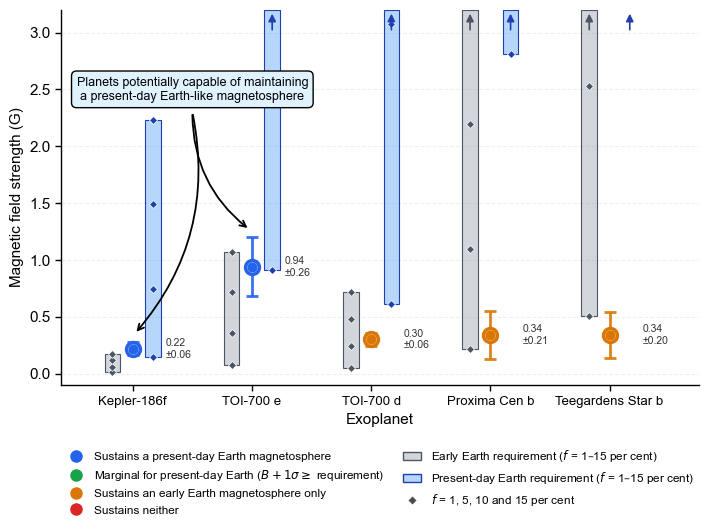

In [127]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from matplotlib.lines import Line2D
from matplotlib.colors import to_rgba

# ---------- estilo ----------
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 11,
    'axes.linewidth': 1.0,
    'xtick.major.width': 1.0, 'ytick.major.width': 1.0,
    'xtick.major.size': 4,    'ytick.major.size': 4,
})

SHOW_TITLE = False        
YMAX = 3.2


C_CURRENT, C_MARGINAL, C_YOUNG_ONLY, C_NONE = '#2563EB', '#16A34A', '#D97706', '#DC2626'
C_BAND_Y, D_BAND_Y = '#9CA3AF', '#4B5563'     
C_BAND_C, D_BAND_C = '#60A5FA', '#1E40AF'     

def get_magnetosphere_color(B_val, sigma_val, Bmin_young, Bmin_current):
    thr_cur, thr_young = min(Bmin_current), min(Bmin_young)    
    if B_val >= thr_cur:
        return C_CURRENT
    elif (B_val + sigma_val) >= thr_cur:
        return C_MARGINAL
    elif (B_val + sigma_val) >= thr_young:
        return C_YOUNG_ONLY
    return C_NONE

names = [p[0] for p in exoplanets]
B     = np.array([p[1] for p in exoplanets])
sigma = np.array([p[2] for p in exoplanets])
x     = np.arange(len(names))
colors = [get_magnetosphere_color(B[i], sigma[i], exoplanets[i][3], exoplanets[i][4])
          for i in range(len(exoplanets))]

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.grid(axis='y', linestyle='--', alpha=0.3, linewidth=0.8, color='#cccccc', zorder=0)
ax.set_axisbelow(True)

W, DX = 0.13, 0.17        


for i, p in enumerate(exoplanets):
    for vals, xc, face, dark in (
            (np.asarray(p[3]), i - DX, C_BAND_Y, D_BAND_Y),    
            (np.asarray(p[4]), i + DX, C_BAND_C, D_BAND_C)):   
        lo, hi = vals.min(), vals.max()
        if lo < YMAX:
            ax.add_patch(Rectangle((xc - W/2, lo), W, min(hi, YMAX) - lo,
                                   facecolor=to_rgba(face, 0.45), edgecolor=dark,
                                   linewidth=0.8, zorder=2))
            shown = vals[vals <= YMAX]
            ax.scatter(np.full(shown.size, xc), shown, marker='D', s=16,
                       color=dark, edgecolor='white', linewidths=0.5, zorder=3)
        if hi > YMAX:                                         # faixa truncada
            ax.annotate('', xy=(xc, YMAX - 0.01), xytext=(xc, YMAX - 0.2),
                        arrowprops=dict(arrowstyle='-|>', color=dark, lw=1.2), zorder=3)


for i in range(len(x)):
    ax.errorbar(x[i], B[i], yerr=sigma[i], fmt='none', ecolor=colors[i],
                elinewidth=2.0, capsize=4, capthick=2.0, alpha=0.9, zorder=4)
    ax.scatter(x[i], B[i], s=100, c='white', edgecolors=colors[i], linewidths=2.5, zorder=5)
    ax.scatter(x[i], B[i], s=40, c=colors[i], zorder=6)
    ax.text(i + DX + W/2 + 0.04, B[i], f'{B[i]:.2f}\n±{sigma[i]:.2f}',
            ha='left', va='center', fontsize=7.5, color='#333333', zorder=7,
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='none', alpha=0.85))


idx = [i for i, c in enumerate(colors) if c in (C_CURRENT, C_MARGINAL)]
if idx:
    text_x, text_y = float(np.mean(idx)), 2.5
    ax.text(text_x, text_y, 'Planets potentially capable of maintaining\na present-day Earth-like magnetosphere',
            fontsize=9, ha='center', va='center', color='black', zorder=10,
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#e0f2fe', edgecolor='black', linewidth=1))
    for i in idx:
        rad = -0.25 if x[i] < text_x else 0.25
        ax.annotate('', xy=(i, B[i] + sigma[i] + 0.05), xytext=(text_x, text_y - 0.2),
                    arrowprops=dict(arrowstyle='->', connectionstyle=f'arc3,rad={rad}',
                                    color='black', lw=1.3, shrinkB=4), zorder=9)


ax.set_xticks(x)
ax.set_xticklabels(names, fontsize=9.5)
ax.set_ylabel('Magnetic field strength (G)', fontsize=11)
ax.set_xlabel('Exoplanet', fontsize=11)
ax.set_ylim(-0.1, YMAX)
ax.set_xlim(-0.6, len(x) - 0.25)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
if SHOW_TITLE:
    ax.set_title('Predicted magnetic fields vs. magnetosphere requirements',
                 fontsize=12, fontweight='bold', pad=10)

dot = lambda c, l: Line2D([0], [0], marker='o', color='w', markerfacecolor=c,
                          markeredgecolor=c, markersize=8, label=l)
handles = [
    dot(C_CURRENT,    'Sustains a present-day Earth magnetosphere'),
    dot(C_MARGINAL,   r'Marginal for present-day Earth ($B+1\sigma \geq$ requirement)'),
    dot(C_YOUNG_ONLY, 'Sustains an early Earth magnetosphere only'),
    dot(C_NONE,       'Sustains neither'),
    Patch(facecolor=to_rgba(C_BAND_Y, 0.45), edgecolor=D_BAND_Y, label=r'Early Earth requirement ($f$ = 1–15 per cent)'),
    Patch(facecolor=to_rgba(C_BAND_C, 0.45), edgecolor=D_BAND_C, label=r'Present-day Earth requirement ($f$ = 1–15 per cent)'),
    Line2D([0], [0], marker='D', color='w', markerfacecolor='0.3', markeredgecolor='white',
           markersize=5, label=r'$f$ = 1, 5, 10 and 15 per cent'),
]
ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, -0.14),
          ncol=2, frameon=False, fontsize=8.5, handlelength=1.6, columnspacing=1.5)

fig.tight_layout()
fig.savefig('magnetic_fields_fig3.png', dpi=600, bbox_inches='tight', facecolor='white')
fig.savefig('magnetic_fields_fig3.pdf', bbox_inches='tight')      # vetorial para o LaTeX
plt.show()

0.48729599999999995 28.000000000000004


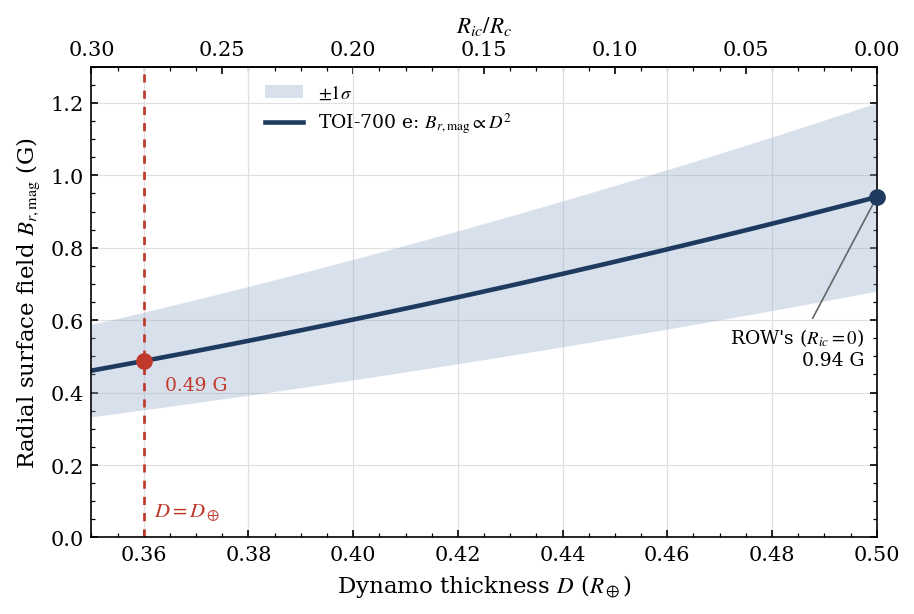

In [5]:
D_earth = 0.36
Rc      = 0.50                 
B_rows  = 0.94                 
sigma   = 0.26                 
B_min   = 0.91                

D = np.linspace(0.35, Rc, 200)
B = B_rows*(D/Rc)**2
rel_err = sigma/B_rows        

plt.rcParams.update({
    'font.family': 'serif', 'mathtext.fontset': 'stix', 'axes.linewidth': 0.8,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.top': False, 'ytick.right': True,
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
})
c_main, c_band, c_earth = '#1f3a5f', '#8fa8c8', '#c0392b'

fig, ax = plt.subplots(figsize=(6.2, 4.2), dpi=150)
ax.fill_between(D, B*(1-rel_err), B*(1+rel_err), color=c_band, alpha=0.35, lw=0,
                label=r'$\pm1\sigma$')
ax.plot(D, B, color=c_main, lw=2.2, label=r'TOI-700 e: $B_{r,\mathrm{mag}}\propto D^{2}$')


ax.axvline(D_earth, ls=(0, (3, 3)), color=c_earth, lw=1.3)
ax.text(D_earth + 0.002, 0.04, r'$D = D_\oplus$', color=c_earth, fontsize=10, ha='left', va='bottom')

B_earth = B_rows*(D_earth/Rc)**2
ax.plot(Rc, B_rows, 'o', color=c_main, ms=7, zorder=5, clip_on=False)
ax.annotate(f"ROW's ($R_{{ic}}=0$)\n{B_rows:.2f} G", xy=(Rc, B_rows),
            xytext=(-6, -62), textcoords='offset points', ha='right', va='top', fontsize=9,
            arrowprops=dict(arrowstyle='-', color='0.4', lw=0.8))
ax.plot(D_earth, B_earth, 'o', color=c_earth, ms=7, zorder=5)
ax.annotate(f'{B_earth:.2f} G', xy=(D_earth, B_earth), xytext=(10, -14),
            textcoords='offset points', ha='left', fontsize=9, color=c_earth)

ax.set_xlim(0.35, Rc); ax.set_ylim(0, 1.3)
ax.set_xlabel(r'Dynamo thickness $D$ ($R_\oplus$)', fontsize=11)
ax.set_ylabel(r'Radial surface field $B_{r,\mathrm{mag}}$ (G)', fontsize=11)
ax.tick_params(labelsize=10, which='both')
ax.grid(True, which='major', color='0.88', lw=0.6)
ax.set_axisbelow(True)

sec = ax.secondary_xaxis('top', functions=(lambda d: 1 - d/Rc, lambda x: Rc*(1 - x)))
sec.set_xlabel(r'$R_{ic}/R_c$', fontsize=11)
sec.tick_params(labelsize=10, direction='in')

ax.legend(fontsize=9, frameon=False, loc='upper left', bbox_to_anchor=(0.20, 1.0))

fig.tight_layout()
fig.savefig('fig_sensibilidade_ric.png', dpi=300)
fig.savefig('fig_sensibilidade_ric.pdf')     # vetorial para o LaTeX
print(B_earth, 100*(1-D_earth/Rc))